In [1]:
import pandas as pd

df = pd.read_csv("regression_data.csv")

In [3]:
for col in df.columns:
    print(col)

hour_local
scheduled_flights
airlines
origins
avg_distance
avg_scheduled_flight_time
temperature_c
wind_max_ms
visibility_min_m
dew_point_spread_c
freezing_deficit_c
high_wind
low_visibility
traffic_low_visibility
hour_sin
hour_cos
season_sin
season_cos
dow_tue
dow_wed
dow_thu
dow_fri
dow_sat
dow_sun
avg_departure_delay


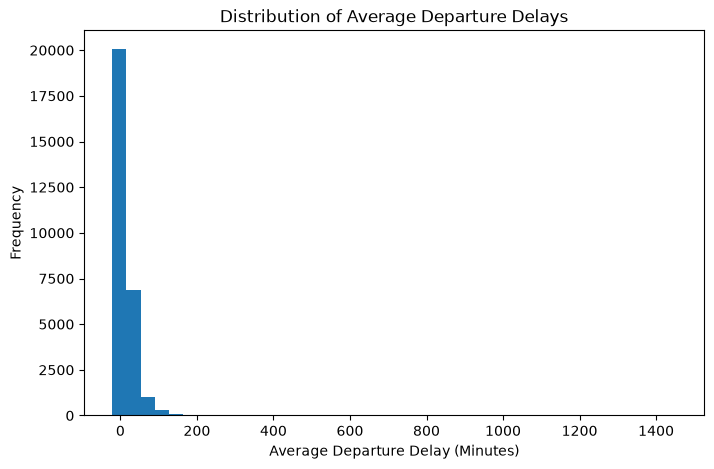

In [7]:
# Graph of average departure delays
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df["avg_departure_delay"], bins=40)
plt.title("Distribution of Average Departure Delays")
plt.xlabel("Average Departure Delay (Minutes)")
plt.ylabel("Frequency")
plt.show()

The distribution of average departure delays is highly right-skewed. Most hourly flight groups experience relatively small delays, while a small number of observations experience exceptionally large delays. These extreme values suggest that severe weather, operational disruptions, or other unusual events occasionally produce substantial delays.

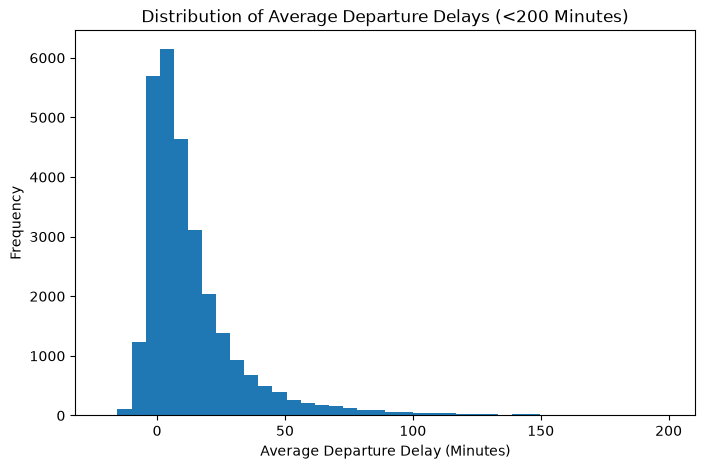

In [8]:
# Graph of average depature delays w/ delays < 200 min
plt.figure(figsize=(8,5))

plt.hist(
    df[df["avg_departure_delay"] < 200]["avg_departure_delay"],
    bins=40
)

plt.title("Distribution of Average Departure Delays (<200 Minutes)")
plt.xlabel("Average Departure Delay (Minutes)")
plt.ylabel("Frequency")

plt.show()

The distribution of average departure delays is strongly right-skewed. Most observations experience relatively small delays, while a smaller number of observations experience much larger delays. Extreme delay events are uncommon but contribute to a long right tail in the distribution.

In [11]:
# Summary statistics for average departure delays
df["avg_departure_delay"].describe()

count    28499.000000
mean        14.521638
std         28.686485
min        -21.000000
25%          1.103672
50%          7.641026
75%         18.472953
max       1452.000000
Name: avg_departure_delay, dtype: float64

The distribution of average departure delays is highly right-skewed. While the median delay is only 7.6 minutes, extreme delay events reaching over 1,400 minutes pull the mean upward to 14.5 minutes. This suggests that most flight hours experience relatively modest delays, but occasional severe disruptions can generate exceptionally large delays.

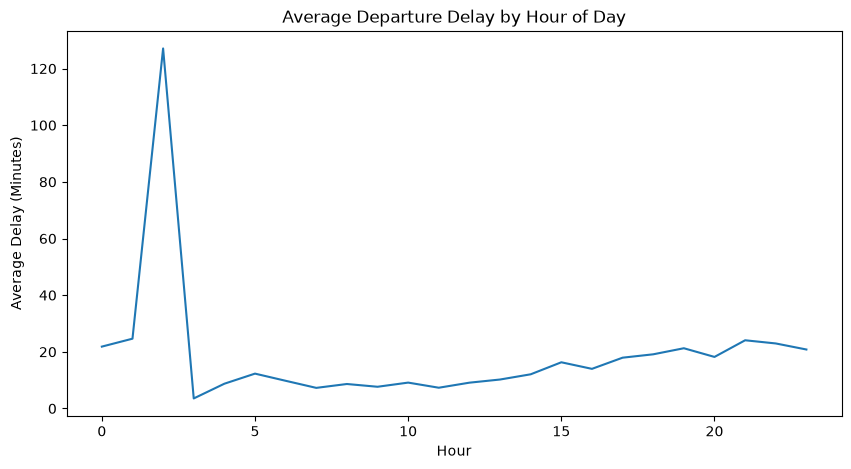

In [12]:
# Hourly delay pattern
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df["hour"] = pd.to_datetime(df["hour_local"]).dt.hour

hourly = (
    df.groupby("hour")["avg_departure_delay"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(10,5))
sns.lineplot(data=hourly, x="hour", y="avg_departure_delay")

plt.title("Average Departure Delay by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Average Delay (Minutes)")

plt.show()

In [10]:
df["hour"] = pd.to_datetime(df["hour_local"]).dt.hour

df.groupby("hour").size()

hour
0     1324
1      521
2       29
3       39
4     1296
5     1331
6     1332
7     1331
8     1331
9     1331
10    1331
11    1330
12    1329
13    1331
14    1329
15    1330
16    1331
17    1332
18    1332
19    1332
20    1332
21    1331
22    1332
23    1332
dtype: int64

This line graph hows average departure delay by hour of day. Most hours have average delays below 25 minutes. The large spike at 2:00 AM should be interpreted cautiously because there are only 29 observations during that hour, compared to roughly 1,300 observations for most other hours. Excluding this anomaly, average departure delays tend to be lower during the morning and somewhat higher during the late afternoon and evening. One possible explanation is that disruptions earlier in the day may affect later flights, although additional analysis would be needed to confirm this.

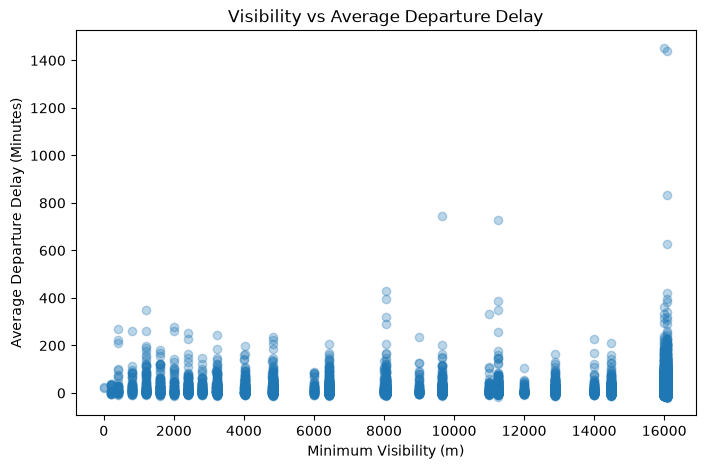

In [13]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["visibility_min_m"],
    df["avg_departure_delay"],
    alpha=0.3
)

plt.xlabel("Minimum Visibility (m)")
plt.ylabel("Average Departure Delay (Minutes)")
plt.title("Visibility vs Average Departure Delay")

plt.show()

The scatterplot indicates a weak negative relationship between visibility and average departure delay. As visibility increases, departure delays tend to decrease slightly, although the effect is small. Considerable variation remains at all visibility levels, and several extreme delay events occur even when visibility is relatively high. This suggests that visibility may contribute to delays but is unlikely to fully explain variation in departure delay on its own.

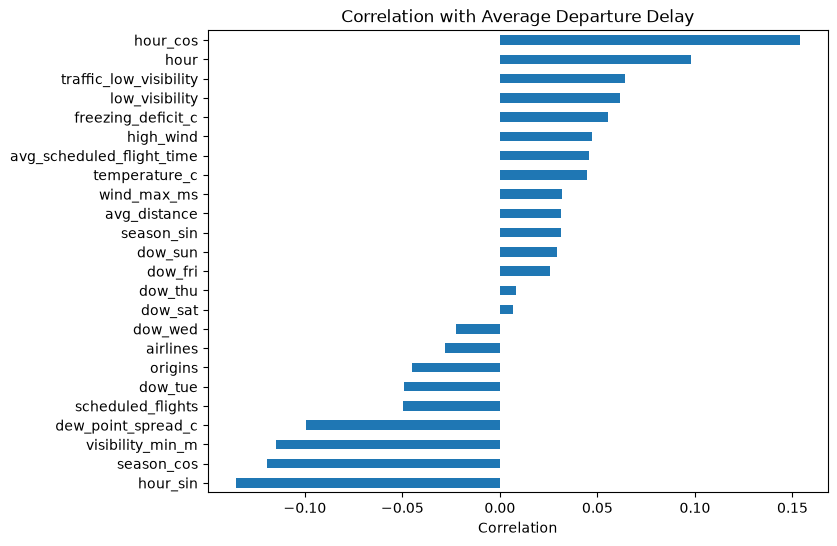

In [16]:
corrs = (
    df.corr(numeric_only=True)["avg_departure_delay"]
      .drop("avg_departure_delay")
      .sort_values()
)

corrs.plot(
    kind="barh",
    figsize=(8,6)
)

plt.title("Correlation with Average Departure Delay")
plt.xlabel("Correlation")

plt.show()

This displays the correlation between each predictor and average departure delay. The strongest positive correlations were observed for hour_cos and hour, suggesting that time-of-day effects may be associated with delay patterns. Visibility showed one of the strongest negative correlations, indicating that lower visibility conditions tend to be associated with higher delays.
However, all correlations were relatively weak, with absolute values below 0.20. This suggests that no single variable is a strong standalone predictor of departure delay. Instead, flight delays likely result from the combined influence of multiple operational, weather, and scheduling factors. These findings motivate the use of more advanced predictive models that can capture interactions between variables.


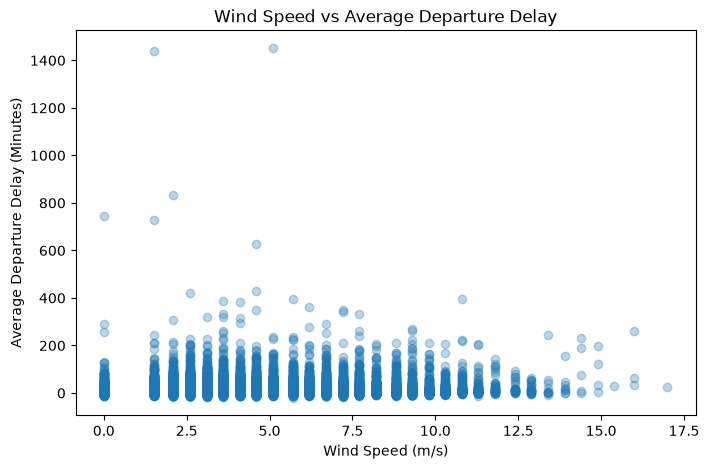

In [14]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["wind_max_ms"],
    df["avg_departure_delay"],
    alpha=0.3
)

plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Average Departure Delay (Minutes)")
plt.title("Wind Speed vs Average Departure Delay")

plt.show()

The relationship between wind speed and average departure delay appears weak. Although some large delay events occur at moderate wind speeds, there is no clear pattern showing that delays systematically increase as wind speed increases. This finding is consistent with the low correlation coefficient between wind speed and average departure delay, suggesting that wind speed alone is not a strong predictor of delays.

In [15]:
corrs = df.corr(numeric_only=True)["avg_departure_delay"]
corrs.sort_values(ascending=False)

avg_departure_delay          1.000000
hour_cos                     0.153620
hour                         0.098184
traffic_low_visibility       0.064234
low_visibility               0.061613
freezing_deficit_c           0.055173
high_wind                    0.047474
avg_scheduled_flight_time    0.045591
temperature_c                0.044843
wind_max_ms                  0.031968
avg_distance                 0.031489
season_sin                   0.031251
dow_sun                      0.029205
dow_fri                      0.025883
dow_thu                      0.008397
dow_sat                      0.006687
dow_wed                     -0.022603
airlines                    -0.028105
origins                     -0.045046
dow_tue                     -0.049302
scheduled_flights           -0.049538
dew_point_spread_c          -0.099211
visibility_min_m            -0.114608
season_cos                  -0.119355
hour_sin                    -0.135331
Name: avg_departure_delay, dtype: float64

The correlation analysis indicates that no individual variable has a strong linear relationship with average departure delay. The strongest positive correlation was observed for hour_cos (0.154), while the strongest negative correlations were observed for hour_sin (-0.135), season_cos (-0.119), and visibility_min_m (-0.115). The relatively small magnitude of all correlation coefficients suggests that departure delays are influenced by multiple factors rather than a single dominant predictor.

What did we try?
We performed exploratory data analysis on the cleaned flight and weather dataset. Specifically, we examined the distribution of departure delays, investigated how delays varied by hour of the day, explored relationships between weather variables and delays, and analyzed correlations between predictors and average departure delay.

Why did we try it?
Exploratory data analysis helps identify patterns, outliers, and potential predictor variables before building predictive models. Understanding these relationships can guide feature selection and model development.

What did we find?
The distribution of departure delays was highly right-skewed, with a median delay of 7.6 minutes and several extreme delay events exceeding 1,000 minutes. Average delays tended to be higher during evening hours than morning hours. Visibility showed a weak negative relationship with delays, while wind speed exhibited little apparent relationship. Correlation analysis showed that no individual variable had a strong linear relationship with departure delay.

What does it mean?
These results suggest that flight delays are influenced by multiple factors rather than a single dominant predictor. Time-of-day effects appear more important than individual weather measures, but even the strongest correlations were relatively weak. This motivates the use of more advanced predictive models that can simultaneously account for multiple variables and their interactions.

Key Findings:
Departure delays are highly right-skewed, with a median delay of 7.6 minutes and a maximum delay of 1,452 minutes.
Most flight hours experience relatively modest delays, although rare extreme events can occur.
Average delays tend to be higher during afternoon and evening hours than during morning hours.
Visibility exhibits a weak negative relationship with departure delays, while wind speed shows little relationship.
No individual predictor displays a strong correlation with departure delay, suggesting that delays are influenced by multiple factors simultaneously.